In [89]:
import pandas as pd
import numpy as np
import warnings
from IPython.display import display

warnings.filterwarnings('ignore')
seed = 21
path = 'zindi-new-user-engagement/'

In [90]:
CompetitionPartipation = pd.read_csv(path + "CompetitionPartipation.csv")
UserActivity = pd.read_csv(path + "UserActivity.csv")
Competition = pd.read_csv(path + "Competition.csv")
Blogs = pd.read_csv(path + "Blogs.csv")
SampleSubmission = pd.read_csv(path + "SampleSubmission.csv")
VariableDefinitions = pd.read_csv(path + "VariableDefinitions.csv")
Users = pd.read_csv(path + "Users.csv")
Discussion = pd.read_csv(path + "Discussion.csv")
Jobs = pd.read_csv(path + "Users.csv")
Comments = pd.read_csv(path + "Comments.csv")

display(
#     "CompetitionPartipation", CompetitionPartipation,
    "UserActivity", UserActivity,
    "Users", Users, 
    # "Competition", Competition,
    # "Blogs", Blogs,
    # "Jobs", Jobs,
    # "Discussion", Discussion,
    # "Comments", Comments,
    # "VariableDefinitions", VariableDefinitions, 
    "SampleSubmission", SampleSubmission,
)

'UserActivity'

,User_ID,Title,datetime time,datetime Year,datetime Month,datetime Day_of_month
0,ID_RT43AK77,comp_ID_IV5D,22:00:38,1,11,22
1,ID_RT43AK77,comp_ID_IV5D,00:41:02,1,11,23
2,ID_RT43AK77,comp_ID_IV5D,00:53:15,1,11,23
3,ID_RT43AK77,comp_ID_IV5D,01:23:05,1,11,23
4,ID_RT43AK77,comp_ID_IV5D,01:27:38,1,11,23
...,...,...,...,...,...,...
317287,ID_Z759BCS3,job_ID_5ONI,07:14:47,1,11,14
317288,ID_WNJMADF8,job_ID_5ONI,06:24:46,1,11,14
317289,ID_7NBY9MV2,job_ID_5ONI,11:56:35,1,11,20
317290,ID_LHPJJSOK,job_ID_5ONI,01:27:13,1,11,14


'Users'

,FeatureX,FeatureY,User_ID,Countries_ID,Created At time,Created At Year,Created At Month,Created At Day_of_month
0,0,0,ID_DC6S4E9O,X9GR,19:33:13.663391,1,1,16
1,1,0,ID_E8S97OUT,X9GR,22:18:18.228921,1,12,27
2,0,0,ID_QZ1HASL3,X9GR,23:13:03.266635,1,1,1
3,1,0,ID_SDV9Q3E9,X9GR,09:50:09.697573,1,12,27
4,1,0,ID_W942LN7F,X9GR,13:33:06.531662,1,1,16
...,...,...,...,...,...,...,...,...
12408,0,1,ID_C5393PD0,7DKX,05:02:39.352427,1,11,6
12409,0,1,ID_QX7XRT0C,K4DG,02:50:19.027320,1,3,25
12410,0,1,ID_RGN2RK66,ONON,22:06:33.713692,1,12,7
12411,0,0,ID_XZS1QE0W,3YQR,06:56:02.570173,1,5,27


'SampleSubmission'

,User_ID_Next_month_Activity,Active
0,ID_4TOXNBGB_Month_5,0
1,ID_CHFTIP26_Month_5,0
2,ID_FU5GMWLQ_Month_5,0
3,ID_254TVBQP_Month_5,0
4,ID_4ENO2VFE_Month_5,0
...,...,...
1335,ID_PI8N2KJX_Month_5,0
1336,ID_L9AHTUD7_Month_5,0
1337,ID_BB7GLV87_Month_5,0
1338,ID_WB6O1NFS_Month_5,0


In [91]:
UserActivity.describe(include='all')

,User_ID,Title,datetime time,datetime Year,datetime Month,datetime Day_of_month
count,317292,317292,317292,317292.0,317292.000000,317292.000000
unique,10400,397,78241,NaN,NaN,NaN
top,ID_CEDNKSVV,Viewed All Competitions,15:29:02,NaN,NaN,NaN
freq,5169,58176,25,NaN,NaN,NaN
mean,NaN,NaN,NaN,1.0,4.462274,16.135462
std,NaN,NaN,NaN,0.0,3.660884,8.890560
min,NaN,NaN,NaN,1.0,1.000000,1.000000
25%,NaN,NaN,NaN,1.0,2.000000,8.000000
50%,NaN,NaN,NaN,1.0,3.000000,16.000000
75%,NaN,NaN,NaN,1.0,5.000000,24.000000


In [92]:
UserActivity['datetime Month'].value_counts()

2     61181
1     58292
5     57258
3     56323
12    42047
4     26962
11    15229
Name: datetime Month, dtype: int64

there are 7 months that are given on the activity set

In [93]:
set(UserActivity[UserActivity['datetime Month'] == 5].User_ID.unique()).\
    intersection(set(SampleSubmission.User_ID_Next_month_Activity.str.replace('_Month_5', '')))

set()

since there is no intersection between the submission file ids and the user activities ids, we need to predict the user activities for the ids that are on the samplesubmission file

In [94]:
UserActivity.Title.value_counts()

Viewed All Competitions            58176
Viewed All Discussions             47172
Viewed All Learning Pages          22930
Downloaded Competition Datafile    19578
Updated Profile                    14748
                                   ...  
comp_ID_TJK9                           1
comp_ID_TBXU                           1
blog_ID_NVX3                           1
blog_ID_R97T                           1
blog_ID_22WI                           1
Name: Title, Length: 397, dtype: int64

In [95]:
# lets reduce the types of activities by removing the ids from them
def remove_id(x):
    x = x.replace('$', '')
    if 'ID' in x:
        return "_".join(x.split('_')[:-1])
    
    return x.replace(' ', '_')

UserActivity.Title.apply(remove_id).value_counts()

Viewed_All_Competitions                 58176
comp_ID                                 55540
Viewed_All_Discussions                  47172
Viewed_All_Learning_Pages               22930
Downloaded_Competition_Datafile         19578
Updated_Profile                         14748
Created_Submission                      13649
identify                                12339
Signed_Up                               10862
create_alias                             9346
badge_OCZE                               8864
Confirmed_Email                          8818
Updated_Discussion                       6498
Joined_Competition                       6086
Viewed_All_Jobs                          4139
Signed_In                                4100
Updated_Submission                       2929
blog_ID                                  2712
badge_HYIO                               1760
Signed_Out                               1660
job_ID                                   1492
Viewed_Discussion                 

In [96]:
UserActivity['main_activities'] = UserActivity.Title.apply(remove_id)
UserActivity.main_activities.unique()

array(['comp_ID', 'job_ID', 'blog_ID', 'create_alias', 'identify',
       'Signed_Up', 'Viewed_All_Competitions', 'Viewed_All_Discussions',
       'Viewed_All_Learning_Pages', 'Confirmed_Email',
       'Joined_Competition', 'Downloaded_Competition_Datafile',
       'Signed_In', 'Updated_Discussion', 'Joined_Team',
       'Created_Submission', 'Viewed_Discussion', 'Updated_Submission',
       'Signed_Out', 'badge_OCZE', 'Updated_Profile', 'Viewed_FAQ',
       'Viewed_All_Jobs', 'Created_Team', 'Invited_Member_To_Team',
       'Updated_Team', 'Updated_Comment',
       'Updated_Discussion_Team_Participants', 'badge_HYIO', 'badge_MLPD',
       'Applied_To_Job', 'Votes_(Up/Down)', 'Transferred_Team_Leadership',
       'badge_PLDS', 'Changed_Password', 'Deleted_Team',
       'Accepted_Team_Leadership_Transfer',
       'Revoked_Team_Leadership_Transfer', 'Report_Something',
       'Kicked_Member_From_Team', 'Left_Team'], dtype=object)

Let's select the activities that are done usually

In [97]:
act_vc = UserActivity.main_activities.value_counts()
selected_activities = act_vc[act_vc > 1000].keys()
selected_activities

Index(['Viewed_All_Competitions', 'comp_ID', 'Viewed_All_Discussions',
       'Viewed_All_Learning_Pages', 'Downloaded_Competition_Datafile',
       'Updated_Profile', 'Created_Submission', 'identify', 'Signed_Up',
       'create_alias', 'badge_OCZE', 'Confirmed_Email', 'Updated_Discussion',
       'Joined_Competition', 'Viewed_All_Jobs', 'Signed_In',
       'Updated_Submission', 'blog_ID', 'badge_HYIO', 'Signed_Out', 'job_ID',
       'Viewed_Discussion'],
      dtype='object')

In [98]:
UserActivity = UserActivity[UserActivity.main_activities.isin(selected_activities)].reset_index(drop=True)
UserActivity

,User_ID,Title,datetime time,datetime Year,datetime Month,datetime Day_of_month,main_activities
0,ID_RT43AK77,comp_ID_IV5D,22:00:38,1,11,22,comp_ID
1,ID_RT43AK77,comp_ID_IV5D,00:41:02,1,11,23,comp_ID
2,ID_RT43AK77,comp_ID_IV5D,00:53:15,1,11,23,comp_ID
3,ID_RT43AK77,comp_ID_IV5D,01:23:05,1,11,23,comp_ID
4,ID_RT43AK77,comp_ID_IV5D,01:27:38,1,11,23,comp_ID
...,...,...,...,...,...,...,...
314600,ID_Z759BCS3,job_ID_5ONI,07:14:47,1,11,14,job_ID
314601,ID_WNJMADF8,job_ID_5ONI,06:24:46,1,11,14,job_ID
314602,ID_7NBY9MV2,job_ID_5ONI,11:56:35,1,11,20,job_ID
314603,ID_LHPJJSOK,job_ID_5ONI,01:27:13,1,11,14,job_ID


In [99]:
# aggregate the number of times that a user has taken per month for each type of activities
dataset = UserActivity.groupby(['User_ID', 'main_activities', 'datetime Month']).size().reset_index().\
    rename(columns={0: 'count'}).\
        sort_values(['User_ID', 'datetime Month', 'count'], ascending=False)

dataset    

,User_ID,main_activities,datetime Month,count
111314,ID_ZZVUJ45W,Downloaded_Competition_Datafile,3,3
111318,ID_ZZVUJ45W,Viewed_All_Discussions,3,2
111313,ID_ZZVUJ45W,Confirmed_Email,3,1
111315,ID_ZZVUJ45W,Joined_Competition,3,1
111316,ID_ZZVUJ45W,Signed_Up,3,1
...,...,...,...,...
1,ID_000H9XOP,Viewed_All_Competitions,5,1
2,ID_000H9XOP,Viewed_All_Discussions,5,1
3,ID_000H9XOP,comp_ID,5,1
4,ID_000H9XOP,create_alias,5,1


We can have a model to train on the user activities on 

In [100]:
dataset.User_ID.nunique(), dataset[dataset['datetime Month'] == 5].User_ID.nunique(),  SampleSubmission.User_ID_Next_month_Activity.nunique()

(10400, 2203, 1340)

Only for the 3.5k users the information is required but to have more data we need to include users that have activities on past months

In [101]:
dataset.main_activities.nunique()

22

we will build a model to predict the number of time that a user will take any of the 22 actions and from that we'll predict the user's engagement

In [118]:
Selected_users = dataset[['User_ID']].drop_duplicates().reset_index(drop=True)
# add ids from SampleSubmission file that are not in the Selected users
# Selected_users = Selected_users.append(pd.DataFrame(SampleSubmission.User_ID_Next_month_Activity.str.replace('_Month_5', '').unique(), columns=['User_ID']), ignore_index=True)
Selected_users

,User_ID
0,ID_ZZVUJ45W
1,ID_ZZUNZJ2U
2,ID_ZZQK0LU6
3,ID_ZZMHNLNT
4,ID_ZZJKFBR5
...,...
10395,ID_00ETFE7J
10396,ID_008D2J6C
10397,ID_004UKSJV
10398,ID_003YJHQA


In [119]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

Users.Countries_ID = Users.Countries_ID.fillna('unspecified')
Users.Countries_ID = le.fit_transform(Users.Countries_ID)
user_df = pd.merge(Selected_users, Users, on='User_ID',  how='inner')
user_df.drop(columns=['Created At time', 'Created At Year'], inplace=True)
user_df

,User_ID,FeatureX,FeatureY,Countries_ID,Created At Month,Created At Day_of_month
0,ID_ZZVUJ45W,0,0,146,3,5
1,ID_ZZUNZJ2U,0,0,146,2,30
2,ID_ZZQK0LU6,0,3,146,3,29
3,ID_ZZMHNLNT,0,0,146,4,1
4,ID_ZZJKFBR5,0,1,143,12,8
...,...,...,...,...,...,...
10395,ID_00ETFE7J,0,0,61,1,6
10396,ID_008D2J6C,0,0,60,1,7
10397,ID_004UKSJV,0,0,69,12,28
10398,ID_003YJHQA,0,1,60,4,12


In [120]:
all_activities = dataset.main_activities.unique()
month_cols = [f'datetime Month_{i}' for i in [1, 2, 3, 4, 5, 11, 12]]
test_ids = SampleSubmission.User_ID_Next_month_Activity.str.replace('_Month_5', '').unique()

activity_df = user_df[['User_ID']]

for activity in all_activities:
    _df = pd.get_dummies(
        dataset[dataset.main_activities == activity].drop(columns='main_activities').reset_index(drop=True),
        columns=['datetime Month'])
    for col in month_cols:
        if col not in _df.columns:
            _df[col] = 0
        _df[col] *= _df['count']
    _df = _df.drop(columns='count')
    # accumulate the counts
    _df = _df.groupby('User_ID').sum().reset_index()
    # merge with all users
    _df = pd.merge(user_df[['User_ID']], _df, on='User_ID', how='left')
    # fill missing values with 0
    _df[month_cols] = _df[month_cols].fillna(0)
    _df.columns = _df.columns.str.replace('datetime Month_', f'{activity}_month_')

    activity_df = pd.merge(activity_df, _df, on='User_ID', how='left')

# merge with users
activity_df = pd.merge(activity_df, user_df, on='User_ID', how='left')

train_df = activity_df[~activity_df.User_ID.isin(test_ids)].reset_index(drop=True)
test_df = activity_df[activity_df.User_ID.isin(test_ids)].reset_index(drop=True)

display(train_df, test_df)

,User_ID,Downloaded_Competition_Datafile_month_1,Downloaded_Competition_Datafile_month_2,Downloaded_Competition_Datafile_month_3,Downloaded_Competition_Datafile_month_4,Downloaded_Competition_Datafile_month_5,Downloaded_Competition_Datafile_month_11,Downloaded_Competition_Datafile_month_12,Viewed_All_Discussions_month_1,Viewed_All_Discussions_month_2,...,badge_HYIO_month_2,badge_HYIO_month_3,badge_HYIO_month_4,badge_HYIO_month_11,badge_HYIO_month_12,FeatureX,FeatureY,Countries_ID,Created At Month,Created At Day_of_month
0,ID_ZZVUJ45W,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,3,5
1,ID_ZZUNZJ2U,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,2,30
2,ID_ZZQK0LU6,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,3,146,3,29
3,ID_ZZJKFBR5,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,1,143,12,8
4,ID_ZZHDXC1Q,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,2,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9657,ID_00RKDLAX,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,1,6,12,23
9658,ID_00ETFE7J,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,61,1,6
9659,ID_008D2J6C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,60,1,7
9660,ID_004UKSJV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,69,12,28


,User_ID,Downloaded_Competition_Datafile_month_1,Downloaded_Competition_Datafile_month_2,Downloaded_Competition_Datafile_month_3,Downloaded_Competition_Datafile_month_4,Downloaded_Competition_Datafile_month_5,Downloaded_Competition_Datafile_month_11,Downloaded_Competition_Datafile_month_12,Viewed_All_Discussions_month_1,Viewed_All_Discussions_month_2,...,badge_HYIO_month_2,badge_HYIO_month_3,badge_HYIO_month_4,badge_HYIO_month_11,badge_HYIO_month_12,FeatureX,FeatureY,Countries_ID,Created At Month,Created At Day_of_month
0,ID_ZZMHNLNT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,4,1
1,ID_ZWDD4T41,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,1,146,4,21
2,ID_ZUVTLGY7,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,3,146,4,10
3,ID_ZT27LY0Q,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,1,4,6
4,ID_ZQM6PUGO,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,4,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
733,ID_04OT901K,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,4,9
734,ID_04GIS1QZ,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,4,10
735,ID_02F14MDW,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,139,4,14
736,ID_028JJTDW,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,146,4,8


In [105]:
from tqdm import tqdm 

new_train = pd.DataFrame()
for i in tqdm(range(len(train_df))):
    user = train_df.loc[i]
    created_month = user['Created At Month']
    if created_month < 5:
        user_dict = {}
        user_dict['User_ID'] = user['User_ID']
        for activity in all_activities:
            user_dict[f'{activity}'] = user[f'{activity}_month_{created_month}']
        next_month = [created_month+1, 1][created_month == 12]
        user_dict['Active'] = [0, 1][user[[f'{activity}_month_{next_month}' for activity in all_activities]].sum() > 0]

        new_train = new_train.append(user_dict, ignore_index=True)

new_train

100%|██████████| 9662/9662 [00:34<00:00, 282.71it/s]


,User_ID,Downloaded_Competition_Datafile,Viewed_All_Discussions,Confirmed_Email,Joined_Competition,Signed_Up,Viewed_All_Competitions,Viewed_All_Learning_Pages,badge_OCZE,create_alias,...,Viewed_All_Jobs,job_ID,Created_Submission,Signed_Out,Updated_Profile,blog_ID,Viewed_Discussion,Updated_Submission,badge_HYIO,Active
0,ID_ZZVUJ45W,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ID_ZZUNZJ2U,0.0,1.0,1.0,0.0,1.0,3.0,3.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ID_ZZQK0LU6,7.0,4.0,1.0,2.0,1.0,14.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ID_ZZHDXC1Q,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ID_ZYVA36JR,0.0,3.0,1.0,1.0,1.0,4.0,3.0,1.0,1.0,...,0.0,0.0,20.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5231,ID_01BEG5HQ,0.0,2.0,1.0,0.0,1.0,5.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
5232,ID_011YM9VH,0.0,14.0,1.0,1.0,1.0,12.0,7.0,1.0,1.0,...,16.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,1.0
5233,ID_00SL0NNP,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
5234,ID_00ETFE7J,0.0,1.0,1.0,0.0,1.0,0.0,3.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [106]:
new_test = pd.DataFrame()
for i in tqdm(range(len(test_df))):
    user = test_df.loc[i]
    created_month = user['Created At Month']
    user_dict = {}
    user_dict['User_ID'] = user['User_ID']
    for activity in all_activities:
        user_dict[f'{activity}'] = user[f'{activity}_month_{created_month}']

    new_test = new_test.append(user_dict, ignore_index=True)

new_test

100%|██████████| 738/738 [00:04<00:00, 177.81it/s]


,User_ID,Downloaded_Competition_Datafile,Viewed_All_Discussions,Confirmed_Email,Joined_Competition,Signed_Up,Viewed_All_Competitions,Viewed_All_Learning_Pages,badge_OCZE,create_alias,...,Updated_Discussion,Viewed_All_Jobs,job_ID,Created_Submission,Signed_Out,Updated_Profile,blog_ID,Viewed_Discussion,Updated_Submission,badge_HYIO
0,ID_ZZMHNLNT,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ID_ZWDD4T41,0.0,1.0,0.0,0.0,1.0,1.0,3.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
2,ID_ZUVTLGY7,4.0,13.0,1.0,1.0,1.0,5.0,3.0,1.0,0.0,...,0.0,5.0,3.0,20.0,0.0,0.0,0.0,0.0,12.0,0.0
3,ID_ZT27LY0Q,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0
4,ID_ZQM6PUGO,0.0,3.0,0.0,0.0,1.0,2.0,2.0,0.0,1.0,...,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
733,ID_04OT901K,2.0,3.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
734,ID_04GIS1QZ,0.0,2.0,1.0,0.0,1.0,7.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
735,ID_02F14MDW,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0
736,ID_028JJTDW,2.0,2.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0


In [107]:
new_train.Active.value_counts()

0.0    4319
1.0     917
Name: Active, dtype: int64

now we have created the train and test set, lets go for adversarial validation

0    5236
1     738
Name: source, dtype: int64
accuracy is 0.8937238493723849
f1 score  is 0.22085889570552147


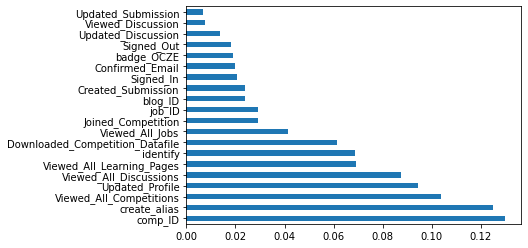

In [108]:
def check_similarity(df1, df2, train_columns):
  from sklearn.metrics import accuracy_score,roc_auc_score,f1_score
  from sklearn.model_selection import train_test_split
  from sklearn.ensemble import RandomForestClassifier
  import matplotlib.pyplot as plt

  d1 = df1.copy()
  d2 = df2.copy()
  d1['source'] = 0
  d2['source'] = 1
  joint_df = pd.concat([d1,d2])
  X = joint_df[train_columns]
  y = joint_df['source']
  print(y.value_counts())
  train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=21, shuffle=True)
  model= RandomForestClassifier(max_depth=15, n_estimators=100, random_state=12)
  model.fit(train_X,train_y)
  print('accuracy is {}'.format(accuracy_score(model.predict(test_X),test_y)))
  print('f1 score  is {}'.format(f1_score(model.predict(test_X),test_y)))
  feat_importances = pd.Series(model.feature_importances_, index=X.columns)
  feat_importances.nlargest(20).plot(kind='barh')
  plt.show()

check_similarity(new_train, new_test, new_train.columns.difference([
  'User_ID', 'Active', 
  # 'Signed_Up_month_4', 'badge_OCZE_month_4', 'create_alias_month_4',
  # 'Confirmed_Email_month_4', 'Viewed_All_Discussions_month_4', 'Viewed_All_Competitions_month_4',
  # 'Viewed_All_Learning_Pages_month_4', 'Updated_Profile_month_4', 'identify_month_4', 'comp_ID_month_4',
  # 'Joined_Competition_month_4', 'Downloaded_Competition_Datafile_month_4', 'Created At Month',
]))

In [109]:
train_df = new_train.reset_index(drop=True)
test_df = new_test.reset_index(drop=True)

In [110]:
main_cols = train_df.columns.difference([
    'User_ID', 'Active', 
    # 'Signed_Up_month_4`', 'badge_OCZE_month_4', 'create_alias_month_4',
    # 'Confirmed_Email_month_4', 'Viewed_All_Discussions_month_4', 'Viewed_All_Competitions_month_4',
    # 'Viewed_All_Learning_Pages_month_4', 'Updated_Profile_month_4', 'identify_month_4', 'comp_ID_month_4',
    # 'Joined_Competition_month_4', 'Downloaded_Competition_Datafile_month_4', 'Created At Month'
])
X = train_df[main_cols]
y = train_df['Active']
test = test_df[main_cols]

In [111]:
# train a model to predict the active users

from sklearn.model_selection import StratifiedKFold
from catboost import CatBoostClassifier, Pool
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score


model = CatBoostClassifier(
    n_estimators=1000,
    learning_rate=0.01124,
    auto_class_weights='Balanced',
    # class_weight='balanced'
)

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
oof = np.zeros(len(train_df))
predictions = []

for fold, (trn_idx, val_idx) in enumerate(skfold.split(X, y)):
    print(f'Fold {fold + 1}')
    X_train, y_train = X.iloc[trn_idx], y.iloc[trn_idx]
    X_valid, y_valid = X.iloc[val_idx], y.iloc[val_idx]
    
    model.fit(
        X_train, y_train,
        eval_set=(X_valid, y_valid),
        verbose=100,
        early_stopping_rounds=100,
    )

    oof[val_idx] = model.predict(X_valid)
    predictions.append(model.predict_proba(test)[:, 1])

predictions = np.mean(predictions, axis=0)
print(f'Our oof f1 score is {f1_score(y, oof)}')

Fold 1
0:	learn: 0.6916769	test: 0.6914452	best: 0.6914452 (0)	total: 11.4ms	remaining: 11.4s
100:	learn: 0.6256971	test: 0.6227403	best: 0.6227403 (100)	total: 292ms	remaining: 2.6s
200:	learn: 0.6073973	test: 0.6068931	best: 0.6068931 (200)	total: 567ms	remaining: 2.25s
300:	learn: 0.5983536	test: 0.6013458	best: 0.6013458 (300)	total: 838ms	remaining: 1.95s
400:	learn: 0.5918018	test: 0.5999827	best: 0.5997526 (375)	total: 1.1s	remaining: 1.65s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.5997526328
bestIteration = 375

Shrink model to first 376 iterations.
Fold 2
0:	learn: 0.6915807	test: 0.6917121	best: 0.6917121 (0)	total: 14.2ms	remaining: 14.2s
100:	learn: 0.6212491	test: 0.6333933	best: 0.6333933 (100)	total: 289ms	remaining: 2.57s
200:	learn: 0.6015144	test: 0.6230426	best: 0.6230426 (200)	total: 559ms	remaining: 2.22s
300:	learn: 0.5917920	test: 0.6207130	best: 0.6206880 (294)	total: 836ms	remaining: 1.94s
400:	learn: 0.5849239	test: 0.6200352	best: 0

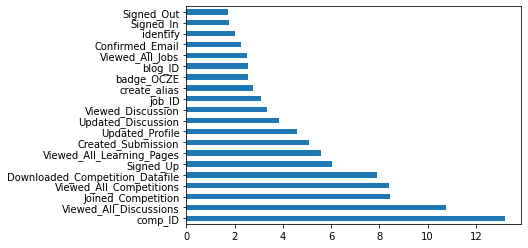

In [112]:
# plot model feature importance

import matplotlib.pyplot as plt
import seaborn as sns

feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(20).plot(kind='barh')
plt.show()

In [113]:
sub = pd.DataFrame({
    'User_ID_Next_month_Activity': test_df.User_ID,
    'Active': predictions
})
sub.Active.describe()

count    738.000000
mean       0.428986
std        0.156612
min        0.171411
25%        0.304184
50%        0.365251
75%        0.538573
max        0.916494
Name: Active, dtype: float64

In [114]:
sub.Active = sub.Active.apply(lambda x: 1 if x > 0.5 else 0)
sub.User_ID_Next_month_Activity = sub.User_ID_Next_month_Activity + '_Month_5'
sub

,User_ID_Next_month_Activity,Active
0,ID_ZZMHNLNT_Month_5,0
1,ID_ZWDD4T41_Month_5,0
2,ID_ZUVTLGY7_Month_5,1
3,ID_ZT27LY0Q_Month_5,0
4,ID_ZQM6PUGO_Month_5,0
...,...,...
733,ID_04OT901K_Month_5,1
734,ID_04GIS1QZ_Month_5,0
735,ID_02F14MDW_Month_5,0
736,ID_028JJTDW_Month_5,1


In [115]:
sub = pd.merge(SampleSubmission.drop(columns='Active'), sub, on='User_ID_Next_month_Activity', how='left').fillna(0)
sub.Active.value_counts()

0.0    1109
1.0     231
Name: Active, dtype: int64

In [116]:
sub.to_csv('submission_3.csv', index=False)

Now the score is 0.411214953 at public leaderboard<br>
Things to add:- 
 - Use more activity types
 - Use the other csv file to add more information about the activities
 - Use more models

 